# Assignment: Crypto Market Dashboard — Data Pipeline & Visualization

**Instructions:**
- This notebook mirrors exactly what was covered in class.
- All context, background, and data definitions are already provided.
- Your job is to **complete the code** in each problem cell where you see `# YOUR CODE HERE`.
- Run each cell after completing it. If the assertions at the bottom pass, you'll see a ✅ message.
- Problem 10 is a Looker Studio task — it has no code to write, but requires you to build and screenshot your dashboard.

---

## 🧩 The Big Picture

You are building a **live crypto market dashboard** — the same pipeline covered in class.

Here is the full pipeline you will implement step by step:

```
CoinGecko API  →  Raw JSON  →  DataFrame  →  Clean & Rename  →  Enrich Data
     →  Summary Matrix  →  Export CSVs  →  Upload to Google Sheets  →  Looker Studio Dashboard
```

By the end of this assignment, you will have:
- Fetched **live** cryptocurrency data from a public API
- Cleaned and enriched it with calculated labels and metrics
- Built a **summary matrix** that powers your dashboard scorecards
- Exported your data as **CSV files** ready for Google Sheets
- Created a **Looker Studio dashboard** with scorecards, a trend chart, and bar charts

---

## ⚙️ Setup: Import Required Libraries

Run this cell first. These are all the libraries you will need throughout the assignment.

- `requests` — to make API calls
- `pandas` — to work with tables of data (DataFrames)
- `datetime` — to add timestamps to your data

In [ ]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime

print("✅ Libraries imported successfully!")

✅ Libraries imported successfully!


---

## Problem 1: Fetch Live Cryptocurrency Data from CoinGecko

**Background:**
CoinGecko is a free cryptocurrency data provider. Unlike most APIs, it does **not** require an API key for basic usage — you can call it directly.

The API endpoint we will use is:
```
https://api.coingecko.com/api/v3/coins/markets
```

You need to send the following **parameters** along with your request:

| Parameter | Value | What it does |
|---|---|---|
| `vs_currency` | `inr` | Returns prices in Indian Rupee |
| `order` | `market_cap_desc` | Largest coins first (by market cap) |
| `per_page` | `50` | Fetch top 50 coins |
| `page` | `1` | First page of results |
| `sparkline` | `false` | Exclude historical price data |

**What a successful response looks like:**
When the API call works, you get back a list of 50 dictionaries. Each dictionary represents one cryptocurrency, like:
```
{
  'id': 'bitcoin',
  'symbol': 'btc',
  'name': 'Bitcoin',
  'current_price': 6800000,
  'market_cap': 134000000000000,
  'total_volume': 2500000000000,
  'high_24h': 6950000,
  'low_24h': 6700000,
  'price_change_percentage_24h': -1.23,
  ...
}
```

**Task:** Complete the function below to fetch data from CoinGecko and return the raw JSON response.

**Requirements:**
- Define the parameters dictionary with all 5 parameters listed above
- Make a GET request to the URL with the parameters
- If the status code is 200, return `response.json()`
- If the status code is anything else, print the status code and return `None`

In [ ]:
def fetch_crypto_data():
    """
    Fetch top 50 cryptocurrencies by market cap from CoinGecko API.

    Returns:
        list: List of 50 cryptocurrency dictionaries if successful, None otherwise
    """
    url = "https://api.coingecko.com/api/v3/coins/markets"

    # YOUR CODE HERE
    params = {
        "vs_currency" : "inr",
        "order" : "market_cap_desc",
        "per_page" : 50,
        "page":1,
        "sparkline" : "False"

    }
    # 1. Create a 'params' dictionary with these keys and values:
    #    'vs_currency': 'inr'
    #    'order': 'market_cap_desc'
    #    'per_page': 50
    #    'page': 1
    #    'sparkline': False
    #

    # 2. Make a GET request:  response = requests.get(url, params=params)
    #
    response = requests.get(url, params=params)

    # 3. If response.status_code == 200:
    #        return response.json()
    #    Else:
    #        print(f"API call failed with status: {response.status_code}")
    #        return None
    if response.status_code == 200:
      return response.json()
    else:
      print(f"API Call failed with status code : {response.status_code}")



# Test your function
raw_data = fetch_crypto_data()
assert raw_data is not None, "API call failed. Check your parameters and try again."
assert isinstance(raw_data, list), "Response should be a list of cryptocurrencies"
assert len(raw_data) == 50, f"Expected 50 coins, got {len(raw_data)}"
assert 'current_price' in raw_data[0], "Each coin should have a 'current_price' field"
assert 'market_cap' in raw_data[0], "Each coin should have a 'market_cap' field"
print("✅ Problem 1 passed!")
print(f"Fetched {len(raw_data)} cryptocurrencies")
print(f"First coin: {raw_data[0]['name']} — ₹{raw_data[0]['current_price']:,}")

✅ Problem 1 passed!
Fetched 50 cryptocurrencies
First coin: Bitcoin — ₹7,440,555


In [ ]:
help(fetch_crypto_data)

Help on function fetch_crypto_data in module __main__:

fetch_crypto_data()
    Fetch top 50 cryptocurrencies by market cap from CoinGecko API.

    Returns:
        list: List of 50 cryptocurrency dictionaries if successful, None otherwise



---

## Problem 2: Convert Raw JSON to a Structured DataFrame

**Background:**
The raw JSON from CoinGecko contains many fields per coin — over 25 columns — but we only need a specific subset for our dashboard. In class, we selected the following columns and kept them:

| Original Column Name | What It Means |
|---|---|
| `id` | Unique coin identifier (e.g., 'bitcoin') |
| `symbol` | Short ticker (e.g., 'btc') |
| `name` | Full name (e.g., 'Bitcoin') |
| `current_price` | Current price in INR |
| `market_cap` | Total market capitalization in INR |
| `total_volume` | Total trading volume in last 24 hours (INR) |
| `high_24h` | Highest price in last 24 hours |
| `low_24h` | Lowest price in last 24 hours |
| `price_change_percentage_24h` | % change in price over last 24 hours |
| `market_cap_rank` | Rank by market cap (1 = largest) |

**Task:** Complete the function to:
1. Convert the raw list of dictionaries into a pandas DataFrame
2. Select only the 10 columns listed above
3. Return the filtered DataFrame

**Hint:** Use `pd.DataFrame(raw_data)` to create the DataFrame, then use double square brackets to select columns.

In [ ]:
def convert_to_dataframe(raw_data):
    """
    Convert raw JSON list to a filtered pandas DataFrame.

    Args:
        raw_data (list): List of cryptocurrency dictionaries from CoinGecko

    Returns:
        DataFrame: Pandas DataFrame with only the 10 required columns
    """

    columns_to_keep = [
        'id', 'symbol', 'name', 'current_price', 'market_cap',
        'total_volume', 'high_24h', 'low_24h',
        'price_change_percentage_24h', 'market_cap_rank'
    ]

    # YOUR CODE HERE
    # 1. Convert raw_data to a DataFrame:  df_raw = pd.DataFrame(raw_data)
    df_raw = pd.DataFrame(raw_data)
    df_raw.shape


    # 2. Select only the columns in 'columns_to_keep':  df = df_raw[columns_to_keep]
    column_to_keep = [
        'id',
        'symbol',
        'name',
        'current_price',
        'market_cap',
        'total_volume',
        'high_24h',
        'low_24h',
        'price_change_percentage_24h',
        'market_cap_rank'
    ]

    # 3. Return df

    df = df_raw[columns_to_keep]

    return df  # Remove this line when you write your code


# Test your function
df_raw = convert_to_dataframe(raw_data)
assert isinstance(df_raw, pd.DataFrame), "Should return a DataFrame"
assert df_raw.shape == (50, 10), f"Expected shape (50, 10), got {df_raw.shape}"
assert 'current_price' in df_raw.columns, "Missing 'current_price' column"
assert 'price_change_percentage_24h' in df_raw.columns, "Missing 'price_change_percentage_24h' column"
print("✅ Problem 2 passed!")
print(f"DataFrame shape: {df_raw.shape}")
print(df_raw.head(3))

✅ Problem 2 passed!
DataFrame shape: (50, 10)
         id symbol      name  current_price       market_cap  total_volume  \
0   bitcoin    btc   Bitcoin     7440555.00  148997890054362  1.619109e+12   
1  ethereum    eth  Ethereum      219422.00   26484450485586  6.718212e+11   
2    tether   usdt    Tether          94.89   17990258539748  3.002364e+12   

    high_24h     low_24h  price_change_percentage_24h  market_cap_rank  
0  7498415.0  7412033.00                      0.19606                1  
1   221557.0   218235.00                      0.35705                2  
2       94.9       94.87                      0.00266                3  


---

## Problem 3: Rename Columns to Meaningful Names

**Background:**
In class, after selecting the columns we need, we renamed them to make the DataFrame more readable and dashboard-friendly. Raw API column names like `price_change_percentage_24h` are accurate but verbose. Good naming makes data easier to understand at a glance.

Here is the rename mapping used in class:

| Old Name | New Name |
|---|---|
| `id` | `coin_id` |
| `symbol` | `symbol` |
| `name` | `coin_name` |
| `current_price` | `price_inr` |
| `market_cap` | `market_cap` |
| `total_volume` | `volume_24h` |
| `high_24h` | `high_24h` |
| `low_24h` | `low_24h` |
| `price_change_percentage_24h` | `change_24h_pct` |
| `market_cap_rank` | `rank` |

**Task:** Complete the function to:
1. Make a copy of the input DataFrame (so you don't modify the original)
2. Rename the columns using the mapping above
3. Return the renamed DataFrame

**Hint:** Use `df.rename(columns={old_name: new_name, ...})` or reassign `df.columns` directly.

In [ ]:
def rename_columns(df):
    """
    Rename DataFrame columns to meaningful names.

    Args:
        df (DataFrame): Raw DataFrame with original CoinGecko column names

    Returns:
        DataFrame: DataFrame with renamed columns
    """

    column_mapping = {
        'id': 'coin_id',
        'symbol': 'symbol',
        'name': 'coin_name',
        'current_price': 'price_inr',
        'market_cap': 'market_cap',
        'total_volume': 'volume_24h',
        'high_24h': 'high_24h',
        'low_24h': 'low_24h',
        'price_change_percentage_24h': 'change_24h_pct',
        'market_cap_rank': 'rank'
    }

    # YOUR CODE HERE
    # 1. Make a copy:  crypto_df = df.copy()

    crypto_df = df.copy()

    # 2. Rename columns using the mapping:  crypto_df = crypto_df.rename(columns=column_mapping)

    crypto_df = crypto_df.rename(columns=column_mapping)
    # 3. Return crypto_df

    return crypto_df

#    pass  # Remove this line when you write your code


# Test your function
crypto_df = rename_columns(df_raw)
expected_columns = ['coin_id', 'symbol', 'coin_name', 'price_inr', 'market_cap',
                    'volume_24h', 'high_24h', 'low_24h', 'change_24h_pct', 'rank']
assert list(crypto_df.columns) == expected_columns, f"Column mismatch. Got: {list(crypto_df.columns)}"
assert len(crypto_df) == 50, "Should still have 50 rows"
print("✅ Problem 3 passed!")
print("Renamed columns:", list(crypto_df.columns))
print(crypto_df[['coin_name', 'price_inr', 'market_cap', 'change_24h_pct']].head(3))

✅ Problem 3 passed!
Renamed columns: ['coin_id', 'symbol', 'coin_name', 'price_inr', 'market_cap', 'volume_24h', 'high_24h', 'low_24h', 'change_24h_pct', 'rank']
  coin_name   price_inr       market_cap  change_24h_pct
0   Bitcoin  7440555.00  148997890054362         0.19606
1  Ethereum   219422.00   26484450485586         0.35705
2    Tether       94.89   17990258539748         0.00266


In [ ]:
crypto_df

,coin_id,symbol,coin_name,price_inr,market_cap,volume_24h,high_24h,low_24h,change_24h_pct,rank
0,bitcoin,btc,Bitcoin,7.440555e+06,148997890054362,1.619109e+12,7.498415e+06,7.412033e+06,0.19606,1
1,ethereum,eth,Ethereum,2.194220e+05,26484450485586,6.718212e+11,2.215570e+05,2.182350e+05,0.35705,2
2,tether,usdt,Tether,9.489000e+01,17990258539748,3.002364e+12,9.490000e+01,9.487000e+01,0.00266,3
3,ripple,xrp,XRP,1.317300e+02,8139246624439,9.967504e+10,1.325600e+02,1.311300e+02,0.04990,4
4,binancecoin,bnb,BNB,5.864100e+04,7903515008141,6.072374e+10,5.888000e+04,5.836200e+04,0.35645,5
5,usd-coin,usdc,USDC,9.491000e+01,7327462885267,4.996153e+11,9.494000e+01,9.488000e+01,0.00807,6
6,solana,sol,Solana,7.956640e+03,4585054153421,1.575410e+11,8.046230e+03,7.932600e+03,-0.08924,7
7,tron,trx,TRON,3.207000e+01,3039663046825,6.903139e+10,3.254000e+01,3.127000e+01,2.02450,8
8,figure-heloc,figr_heloc,Figure Heloc,9.873000e+01,1684257328113,2.679664e+09,9.873000e+01,9.793000e+01,0.71216,9
9,dogecoin,doge,Dogecoin,1.023000e+01,1576976209639,9.717958e+10,1.037000e+01,1.018000e+01,0.08862,10


---

## Problem 4: Categorize Coins by Market Cap Size

**Background:**
Raw market cap numbers like ₹134,000,000,000,000 are hard to interpret quickly. In class, we created a new column called `market_cap_category` that labels each coin based on its market cap value.

Here are the thresholds used (in INR):

| Category | Market Cap Range |
|---|---|
| `Mega Cap` | Greater than ₹10 Trillion (10,000,000,000,000) |
| `Large Cap` | ₹1 Trillion to ₹10 Trillion |
| `Mid Cap` | ₹100 Billion to ₹1 Trillion |
| `Small Cap` | Below ₹100 Billion |

Think of these like size labels for companies: Fortune 500, Large Enterprise, SME, and Startup.

**Task:** Complete the function `categorize_market_cap(market_cap)` that takes a single market cap value and returns the correct category string.

Then, the second cell uses this function to add the `market_cap_category` column to the DataFrame — that part is already written for you.

**Requirements:**
- Return `'Mega Cap'` if market_cap > 10,000,000,000,000
- Return `'Large Cap'` if market_cap > 1,000,000,000,000
- Return `'Mid Cap'` if market_cap > 100,000,000,000
- Return `'Small Cap'` otherwise

**Hint:** Use if / elif / else blocks.

In [ ]:
def categorize_market_cap(market_cap):
    """
    Categorize a cryptocurrency by its market capitalization.

    Args:
        market_cap (float): Market cap value in INR

    Returns:
        str: One of 'Mega Cap', 'Large Cap', 'Mid Cap', 'Small Cap'
    """

    # YOUR CODE HERE
    # if market_cap > 10_000_000_000_000:   → return 'Mega Cap'
    if market_cap >= 10000000000000:
      return 'Mega Cap'
    # elif market_cap > 1_000_000_000_000:  → return 'Large Cap'
    elif market_cap >= 1000000000000:
      return 'Large Cap'
    # elif market_cap > 100_000_000_000:    → return 'Mid Cap'
    elif market_cap >= 100000000000:
      return 'Mid Cap'
    # else:                                 → return 'Small Cap'
    else:
      return 'Small Cap'



# This part applies your function to the whole DataFrame — already written for you
crypto_df['market_cap_category'] = crypto_df['market_cap'].apply(categorize_market_cap)

# Test your function
assert categorize_market_cap(15_000_000_000_000) == 'Mega Cap', "Should be Mega Cap"
assert categorize_market_cap(5_000_000_000_000) == 'Large Cap', "Should be Large Cap"
assert categorize_market_cap(500_000_000_000) == 'Mid Cap', "Should be Mid Cap"
assert categorize_market_cap(50_000_000_000) == 'Small Cap', "Should be Small Cap"
assert 'market_cap_category' in crypto_df.columns, "Column 'market_cap_category' should be in the DataFrame"
assert set(crypto_df['market_cap_category']).issubset({'Mega Cap', 'Large Cap', 'Mid Cap', 'Small Cap'}), "Only valid categories allowed"
print("✅ Problem 4 passed!")
print("\nMarket cap distribution:")
print(crypto_df['market_cap_category'].value_counts())

✅ Problem 4 passed!

Market cap distribution:
market_cap_category
Mid Cap      38
Large Cap     9
Mega Cap      3
Name: count, dtype: int64


---

## Problem 5: Categorize Coins by 24-Hour Performance

**Background:**
The `change_24h_pct` column tells us how much each coin's price moved in the last 24 hours. A coin with +8% is surging; one with -6% is falling. Instead of reading raw numbers, we label each coin's performance into a category.

In class, we used these thresholds:

| Category | Condition |
|---|---|
| `Strong Gainer` | change_24h_pct > 5% |
| `Moderate Gainer` | change_24h_pct > 1% (and ≤ 5%) |
| `Stable` | change_24h_pct between -1% and +1% |
| `Moderate Loser` | change_24h_pct < -1% (and ≥ -5%) |
| `Strong Loser` | change_24h_pct < -5% |

This is like the performance labels on a mutual fund: "Outperformer", "In-line", "Underperformer."

**Task:** Complete the function `categorize_performance(change_pct)` that takes a single percentage value and returns the correct performance label.

Then, the second part applies it to the full DataFrame — already written for you.

In [ ]:
def categorize_performance(change_pct):
    """
    Categorize a coin's 24-hour performance based on price change percentage.

    Args:
        change_pct (float): 24-hour price change in percentage (e.g., 3.5 or -2.1)

    Returns:
        str: One of 'Strong Gainer', 'Moderate Gainer', 'Stable', 'Moderate Loser', 'Strong Loser'
    """

    # YOUR CODE HERE
    # if change_pct > 5:      → return 'Strong Gainer'
    if change_pct > 5:
      return 'Strong Gainer'

    # elif change_pct > 1:    → return 'Moderate Gainer'
    elif change_pct > 1:
      return 'Moderate Gainer'

    # elif change_pct >= -1:  → return 'Stable'
    elif change_pct >= -1:
      return 'Stable'

    # elif change_pct >= -5:  → return 'Moderate Loser'
    elif change_pct >= -5:
      return 'Moderate Loser'

    # else:                   → return 'Strong Loser'

    else :
      return 'Strong Loser'



# Apply to the full DataFrame — already written for you
crypto_df['performance_category'] = crypto_df['change_24h_pct'].apply(categorize_performance)

# Test your function
assert categorize_performance(7.5) == 'Strong Gainer', "Should be Strong Gainer"
assert categorize_performance(2.0) == 'Moderate Gainer', "Should be Moderate Gainer"
assert categorize_performance(0.5) == 'Stable', "Should be Stable"
assert categorize_performance(-3.0) == 'Moderate Loser', "Should be Moderate Loser"
assert categorize_performance(-8.0) == 'Strong Loser', "Should be Strong Loser"
assert 'performance_category' in crypto_df.columns, "Column 'performance_category' should be in the DataFrame"
valid_cats = {'Strong Gainer', 'Moderate Gainer', 'Stable', 'Moderate Loser', 'Strong Loser'}
assert set(crypto_df['performance_category']).issubset(valid_cats), "Only valid performance categories allowed"
print("✅ Problem 5 passed!")
print("\nPerformance distribution:")
print(crypto_df['performance_category'].value_counts())

✅ Problem 5 passed!

Performance distribution:
performance_category
Stable             38
Moderate Gainer     9
Moderate Loser      2
Strong Loser        1
Name: count, dtype: int64


---

## Problem 6: Calculate Volatility Percentage

**Background:**
Volatility tells us how much a coin's price swings within a single day. A coin priced at ₹100 that swings between ₹90 and ₹110 is more volatile than one that swings between ₹98 and ₹102.

We calculate **Volatility %** as:

```
volatility_pct = ( (high_24h - low_24h) / current_price ) × 100
```

For example:
- Current price: ₹6,800,000
- 24h High: ₹6,950,000
- 24h Low: ₹6,700,000
- Price range: 6,950,000 − 6,700,000 = 250,000
- Volatility %: (250,000 / 6,800,000) × 100 = **3.68%**

**Task:** Complete the function to calculate volatility percentage and round the result to 2 decimal places.

Then the result is added to the DataFrame — already written for you.

In [ ]:
def calculate_volatility(row):
    """
    Calculate 24-hour volatility percentage for a single row.

    Args:
        row: A single DataFrame row with 'high_24h', 'low_24h', 'price_inr' columns

    Returns:
        float: Volatility percentage rounded to 2 decimal places
    """

    # YOUR CODE HERE
    if pd.isna(row['high_24h']) or pd.isna(row['low_24h']) or pd.isna(row['price_inr']):
      return 0
    # Formula: ((row['high_24h'] - row['low_24h']) / row['price_inr']) * 100
    Formula = ((row['high_24h'] - row['low_24h'])/ row['price_inr']) * 100
    # Round the result to 2 decimal places using round(..., 2)
    result = round(Formula, 2)
    # Return the rounded value

    return result




# Apply to the full DataFrame — already written for you
crypto_df['volatility_pct'] = crypto_df.apply(calculate_volatility, axis=1)

# Test your function
sample_row = pd.Series({'high_24h': 6_950_000, 'low_24h': 6_700_000, 'price_inr': 6_800_000})
result = calculate_volatility(sample_row)
print(result)
assert abs(result - 3.68) < 0.01, f"Expected ~3.68, got {result}"
assert 'volatility_pct' in crypto_df.columns, "Column 'volatility_pct' should be in the DataFrame"
assert (crypto_df['volatility_pct'] >= 0).all(), "Volatility should always be non-negative"
print("✅ Problem 6 passed!")
print("\nTop 5 most volatile coins:")
print(crypto_df[['coin_name', 'volatility_pct', 'change_24h_pct']].sort_values('volatility_pct', ascending=False).head())

3.68
✅ Problem 6 passed!

Top 5 most volatile coins:
                  coin_name  volatility_pct  change_24h_pct
26                 MemeCore            6.65         1.07076
35                Bittensor            6.58         4.06259
47  World Liberty Financial            5.43         2.15363
48                    Aster            4.97         1.52765
18                    Zcash            4.96         2.93152


---

## Problem 7: Calculate Volume-to-Market-Cap Ratio

**Background:**
The **Volume-to-Market-Cap Ratio** tells us how actively a coin is being traded relative to its size.

Think of it like turnover rate in a store: a shop with ₹1 crore of inventory that sells ₹50 lakh per day has a higher turnover than one that sells ₹1 lakh per day.

Formula:
```
volume_to_mcap = volume_24h / market_cap
```

- A **high ratio** (e.g., 0.15) means there is a lot of trading happening — the coin is "hot"
- A **low ratio** (e.g., 0.01) means relatively little trading — the coin is quiet

This metric is useful for identifying coins that are seeing unusual trading activity.

**Task:** Complete the function below. Round the result to 4 decimal places.

In [ ]:
def calculate_volume_to_mcap(row):
    """
    Calculate the volume-to-market-cap ratio for a single row.

    Args:
        row: A single DataFrame row with 'volume_24h' and 'market_cap' columns

    Returns:
        float: Volume-to-market-cap ratio rounded to 4 decimal places
    """

    # YOUR CODE HERE
    if pd.isna(row['volume_24h']) or pd.isna(row['market_cap']):
      return 0
    # Formula:  row['volume_24h'] / row['market_cap']
    Formula = row['volume_24h']/row['market_cap']
    # Round the result to 4 decimal places using round(..., 4)
    return round(Formula,4)
    # Return the value

    #pass  # Remove this line when you write your code


# Apply to the full DataFrame — already written for you
crypto_df['volume_to_mcap'] = crypto_df.apply(calculate_volume_to_mcap, axis=1)

# Test your function
sample_row = pd.Series({'volume_24h': 2_500_000_000, 'market_cap': 134_000_000_000})
result = calculate_volume_to_mcap(sample_row)
assert abs(result - 0.0187) < 0.001, f"Expected ~0.0187, got {result}"
assert 'volume_to_mcap' in crypto_df.columns, "Column 'volume_to_mcap' should be in the DataFrame"
assert (crypto_df['volume_to_mcap'] >= 0).all(), "Volume-to-mcap should be positive"
print("✅ Problem 7 passed!")
print("\nTop 5 most actively traded coins:")
print(crypto_df[['coin_name', 'volume_to_mcap', 'volume_24h']].sort_values('volume_to_mcap', ascending=False).head())

✅ Problem 7 passed!

Top 5 most actively traded coins:
    coin_name  volume_to_mcap    volume_24h
2      Tether          0.1669  3.002364e+12
21       USD1          0.1245  5.323141e+10
35  Bittensor          0.0870  2.257171e+10
48      Aster          0.0813  1.328345e+10
18      Zcash          0.0775  4.757220e+10


---

## Problem 8: Add an Analysis Timestamp

**Background:**
Every data report should be time-stamped. When your dashboard pulls data and someone asks "when was this fetched?", the timestamp answers that.

In class, we added two columns:
- `fetched_at` — the exact date and time the data was pulled, formatted as `YYYY-MM-DD HH:MM:SS` (e.g., `'2024-04-20 10:35:00'`)
- `fetch_date` — just the date, formatted as `YYYY-MM-DD` (e.g., `'2024-04-20'`)

Both columns should have the **same value for every row** in the DataFrame — since all rows were fetched at the same moment.

**Task:** Complete the function to:
1. Get the current datetime using `datetime.now()`
2. Format `fetched_at` as a string: `now.strftime('%Y-%m-%d %H:%M:%S')`
3. Format `fetch_date` as a string: `now.strftime('%Y-%m-%d')`
4. Add both as new columns to the DataFrame
5. Return the updated DataFrame

In [ ]:
def add_timestamp(df):
    """
    Add fetch timestamp columns to the DataFrame.

    Args:
        df (DataFrame): Enriched cryptocurrency DataFrame

    Returns:
        DataFrame: DataFrame with 'fetched_at' and 'fetch_date' columns added
    """

    # YOUR CODE HERE
    # 1. Get current time:  now = datetime.now()
    now = datetime.now()
    # 2. Create df_copy = df.copy()
    df_copy = df.copy()
    # 3. Add column:  df_copy['fetched_at'] = now.strftime('%Y-%m-%d %H:%M:%S')
    df_copy['fetched_at'] = now.strftime('%Y-%m-%d %H:%M:%S')
    # 4. Add column:  df_copy['fetch_date'] = now.strftime('%Y-%m-%d')
    df_copy['fetch_date'] = now.strftime('%Y-%m-%d')
    # 5. Return df_copy
    return df_copy

#    pass  # Remove this line when you write your code


# Apply the function
crypto_df = add_timestamp(crypto_df)

# Test your function
assert 'fetched_at' in crypto_df.columns, "Column 'fetched_at' should be in the DataFrame"
assert 'fetch_date' in crypto_df.columns, "Column 'fetch_date' should be in the DataFrame"
assert crypto_df['fetched_at'].nunique() == 1, "All rows should have the same fetched_at value"
assert len(crypto_df['fetch_date'].iloc[0]) == 10, "fetch_date should be in YYYY-MM-DD format (10 characters)"
print("✅ Problem 8 passed!")
print(f"\nData fetched at: {crypto_df['fetched_at'].iloc[0]}")
print(f"Total columns in DataFrame: {len(crypto_df.columns)}")
print("All columns:", list(crypto_df.columns))

✅ Problem 8 passed!

Data fetched at: 2026-05-03 10:52:44
Total columns in DataFrame: 16
All columns: ['coin_id', 'symbol', 'coin_name', 'price_inr', 'market_cap', 'volume_24h', 'high_24h', 'low_24h', 'change_24h_pct', 'rank', 'market_cap_category', 'performance_category', 'volatility_pct', 'volume_to_mcap', 'fetched_at', 'fetch_date']


---

## Problem 9: Create a Summary Matrix and Export All CSVs

**Background:**
In class, we created multiple CSV files — each representing a different "slice" of the data — and uploaded them as separate sheets in Google Sheets. These sheets then power the different charts and scorecards in Looker Studio.

Here are the CSV files you need to create:

| File Name | Contents | Powers in Dashboard |
|---|---|---|
| `crypto_full_data.csv` | The complete enriched DataFrame (all columns) | Reference / raw data |
| `performance_breakdown.csv` | Count of coins in each performance category | Pie chart |
| `market_cap_breakdown.csv` | Count of coins in each market cap category | Bar chart |
| `top_10_gainers.csv` | Top 10 coins by highest `change_24h_pct` | Gainers table |
| `top_10_losers.csv` | Bottom 10 coins by lowest `change_24h_pct` | Losers table |
| `summary_matrix.csv` | Single-row summary with key metrics | Scorecards |

**The summary_matrix.csv should have these columns:**

| Column | How to Calculate |
|---|---|
| `total_market_cap` | Sum of all `market_cap` values |
| `avg_change_24h` | Mean of `change_24h_pct`, rounded to 2 decimal places |
| `total_volume` | Sum of all `volume_24h` values |
| `coins_analyzed` | Count of rows (should be 50) |
| `fetch_date` | The fetch_date from any row |

**Task:** Complete the function below to build all 6 CSVs and save them.

In [ ]:
def export_all_csvs(df):
    """
    Create and export all dashboard CSV files.

    Args:
        df (DataFrame): The fully enriched cryptocurrency DataFrame

    Returns:
        dict: Dictionary of {filename: DataFrame} for all 6 exports
    """

    # YOUR CODE HERE — build each DataFrame and save it as a CSV

    # --- 1. Full Data ---
    full_data = df.copy()
    full_data.to_csv('crypto_full_data.csv', index=False)


    # --- 2. Performance Breakdown ---
    # Count how many coins fall into each performance_category
    # Hint: df['performance_category'].value_counts().reset_index()
    # Rename columns to: 'performance_category', 'coin_count'
    # Save as 'performance_breakdown.csv'

    performance_breakdown = (df['market_cap_category'].value_counts().reset_index())
    performance_breakdown.columns=['performance_category','coin_count']
    performance_breakdown.to_csv('performance_breakdown.csv',index=False)


    # --- 3. Market Cap Breakdown ---
    # Count how many coins fall into each market_cap_category
    # Rename columns to: 'market_cap_category', 'coin_count'
    # Save as 'market_cap_breakdown.csv'
    market_cap_breakdown = (df['market_cap_category'].value_counts().reset_index())
    market_cap_breakdown.columns=['market_cap_category', 'coin_count']
    market_cap_breakdown.to_csv('market_cap_breakdown.csv')

    # --- 4. Top 10 Gainers ---
    # Sort by change_24h_pct descending, take top 10
    # Keep columns: ['coin_name', 'symbol', 'price_inr', 'change_24h_pct', 'market_cap_category']
    # Save as 'top_10_gainers.csv'
    columns = ['coin_name', 'symbol', 'price_inr', 'change_24h_pct', 'market_cap_category']
    top_10_gainers = crypto_df.sort_values(by='change_24h_pct',ascending=False)[columns].head(10)
    top_10_gainers.to_csv('top_10_gainers.csv', index=False)

    # --- 5. Top 10 Losers ---
    # Sort by change_24h_pct ascending, take top 10
    # Keep same columns as gainers
    top_10_losers = crypto_df.sort_values(by='change_24h_pct',ascending=True)[columns].head(10)
    top_10_losers.to_csv('top_10_looser.csv',index=False)
    # Save as 'top_10_losers.csv'

    # --- 6. Summary Matrix ---
    # Create a single-row DataFrame with these columns:
    #   'total_market_cap': df['market_cap'].sum()
    #   'avg_change_24h':   round(df['change_24h_pct'].mean(), 2)
    #   'total_volume':     df['volume_24h'].sum()
    #   'coins_analyzed':   len(df)
    #   'fetch_date':       df['fetch_date'].iloc[0]
    # Hint: pd.DataFrame([{ ... }])
    # Save as 'summary_matrix.csv'

    summary_matrix = pd.DataFrame([{
        'total_market_cap': df['market_cap'].sum(),
        'avg_change_24h': round(df['change_24h_pct'].mean(), 2),
        'total_volume': df['volume_24h'].sum(),
        'coins_analyzed': len(df),
        'fetch_date': df['fetch_date'].iloc[0]
    }])

    summary_matrix.to_csv('summary_matrix.csv',index=False)



    # --- Return all DataFrames in a dictionary (already structured for you) ---
    return {
         'crypto_full_data.csv': full_data,
         'performance_breakdown.csv': performance_breakdown,
         'market_cap_breakdown.csv': market_cap_breakdown,
         'top_10_gainers.csv': top_10_gainers,
         'top_10_losers.csv': top_10_losers,
         'summary_matrix.csv': summary_matrix
    }



# Run the export
exported = export_all_csvs(crypto_df)

# Test your exports
assert isinstance(exported, dict), "Should return a dictionary"
assert len(exported) == 6, f"Expected 6 files, got {len(exported)}"
assert 'summary_matrix.csv' in exported, "Missing summary_matrix.csv"
assert 'top_10_gainers.csv' in exported, "Missing top_10_gainers.csv"
assert 'top_10_losers.csv' in exported, "Missing top_10_losers.csv"
assert len(exported['top_10_gainers.csv']) == 10, "Gainers should have exactly 10 rows"
assert len(exported['top_10_losers.csv']) == 10, "Losers should have exactly 10 rows"
sm = exported['summary_matrix.csv']
assert 'total_market_cap' in sm.columns, "Summary matrix missing 'total_market_cap'"
assert 'avg_change_24h' in sm.columns, "Summary matrix missing 'avg_change_24h'"
assert sm['coins_analyzed'].iloc[0] == 50, "coins_analyzed should be 50"
print("✅ Problem 9 passed!")
print("\n📁 Files exported:")
for fname, df_out in exported.items():
    print(f"   {fname}  →  {df_out.shape[0]} rows × {df_out.shape[1]} cols")
print("\n📊 Summary Matrix:")
print(exported['summary_matrix.csv'].to_string(index=False))

✅ Problem 9 passed!

📁 Files exported:
   crypto_full_data.csv  →  50 rows × 16 cols
   performance_breakdown.csv  →  3 rows × 2 cols
   market_cap_breakdown.csv  →  3 rows × 2 cols
   top_10_gainers.csv  →  10 rows × 5 cols
   top_10_losers.csv  →  10 rows × 5 cols
   summary_matrix.csv  →  1 rows × 5 cols

📊 Summary Matrix:
 total_market_cap  avg_change_24h  total_volume  coins_analyzed fetch_date
  244454753661369            0.31  6.641040e+12              50 2026-05-03


---

## Problem 10: Build the Looker Studio Dashboard

> **No code required for this problem.** This is a hands-on Looker Studio task.

---

### Step-by-Step Instructions

Now that your CSV files are ready, follow these steps to build a dashboard exactly like the one shown in class.

---

**Step 1 — Upload CSVs to Google Sheets**
1. Open [Google Sheets](https://sheets.google.com) and create a new spreadsheet. Name it **`Crypto Dashboard Data`**.
2. Import each CSV as a separate tab (sheet):
   - Go to `File → Import → Upload`
   - Upload `summary_matrix.csv` → rename the tab to **Summary Matrix**
   - Upload `performance_breakdown.csv` → rename to **Performance Breakdown**
   - Upload `market_cap_breakdown.csv` → rename to **Market Cap Breakdown**
   - Upload `top_10_gainers.csv` → rename to **Top 10 Gainers**
   - Upload `top_10_losers.csv` → rename to **Top 10 Losers**
   - Upload `crypto_full_data.csv` → rename to **Full Data**

---

**Step 2 — Create a New Looker Studio Report**
1. Go to [Looker Studio](https://lookerstudio.google.com) and click **"Create" → "Report"**.
2. Connect the first data source: Choose **Google Sheets**, select your `Crypto Dashboard Data` spreadsheet, and pick the **Summary Matrix** tab.
3. Click **"Add More Data"** to connect the remaining five sheets one by one.

---

**Step 3 — Set Up the Theme and Layout**
- Background color: Light grey (`#F5F5F5`)
- Canvas size: **1200 × 900 px**
- Add a **dark rectangle** at the top as a header
- Inside the header, add a **text box** with the title: **Crypto Market Dashboard — Live**

---

**Step 4 — Add Four Scorecards** (connect to **Summary Matrix** sheet)

| Scorecard | Metric | Aggregation | Color Hint |
|---|---|---|---|
| Total Market Cap | `total_market_cap` | Sum | Neutral |
| Avg 24h Change | `avg_change_24h` | Average | Green if positive, red if negative |
| Total Volume | `total_volume` | Sum | Neutral |
| Coins Analyzed | `coins_analyzed` | Sum | Neutral |

**Tip:** Give each scorecard a clear title label and make them equal in size. Arrange all four in a single row.

---

**Step 5 — Add a Pie Chart** (connect to **Performance Breakdown** sheet)
- Dimension: `performance_category`
- Metric: `coin_count`
- Title: **Market Sentiment Distribution**
- Place it on the left half of the canvas below the scorecards

---

**Step 6 — Add a Bar Chart** (connect to **Market Cap Breakdown** sheet)
- Dimension: `market_cap_category`
- Metric: `coin_count`
- Title: **Coins by Market Cap Size**
- Place it on the right half of the canvas, next to the pie chart

---

**Step 7 — Add Two Tables with Conditional Formatting**

**Top 10 Gainers Table** (connect to **Top 10 Gainers** sheet)
- Columns to show: `coin_name`, `symbol`, `change_24h_pct`, `price_inr`
- Apply conditional formatting on `change_24h_pct`: **green background** if value > 0
- Title: **🚀 Top 10 Gainers**

**Top 10 Losers Table** (connect to **Top 10 Losers** sheet)
- Same columns as above
- Apply conditional formatting on `change_24h_pct`: **red background** if value < 0
- Title: **📉 Top 10 Losers**

---

**Step 8 — Final Polish**
- Align all elements neatly
- Ensure all charts and tables have clear, descriptive titles
- Use color intentionally: red = risk/loss, green = gain, neutral for informational data
- Preview your dashboard using the **"View"** button in Looker Studio

---

### ✅ Submission for Problem 10

When your dashboard is complete:
1. Take a **screenshot** of the full dashboard
2. Paste the screenshot in the cell below using `Insert → Image` in Google Colab
3. Also paste your **Looker Studio shareable link** in the text cell below

---

### Your Dashboard Screenshot & Link

**Looker Studio Link:**
> https://datastudio.google.com/reporting/515628f6-cd4e-4ee0-aefe-15099528328a

**Dashboard Screenshot:**
> 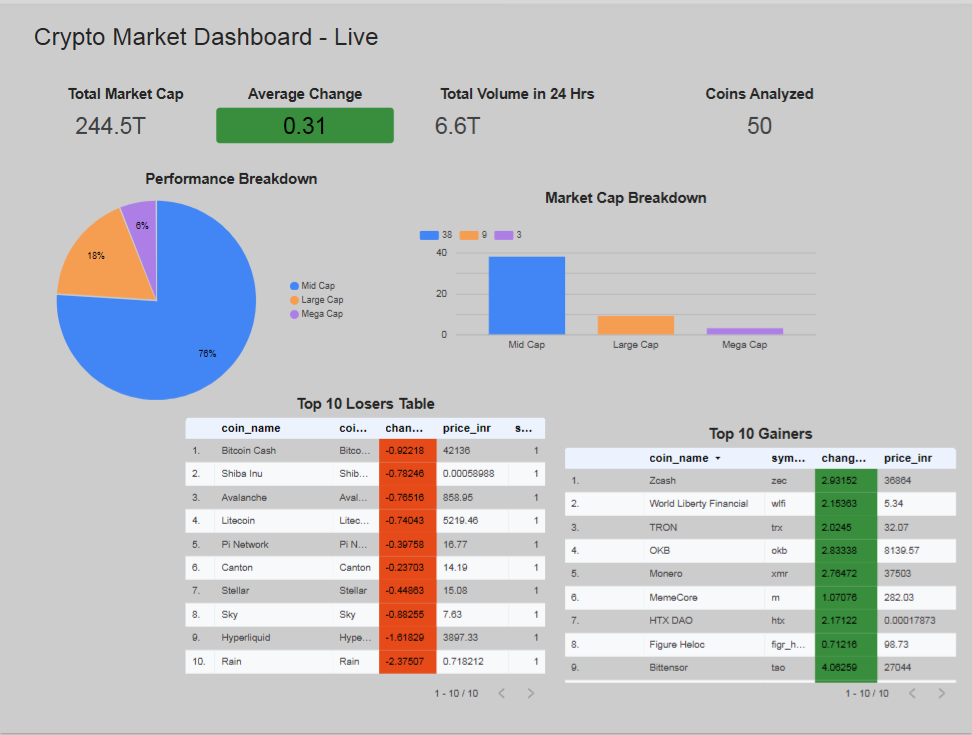

---

## 🎉 Assignment Complete!

If all your tests passed and your dashboard is built, you have successfully implemented a **live crypto market data pipeline** — from raw API to a visual dashboard.

### What You Built:
1. ✅ Fetched live data from a real public API (CoinGecko)
2. ✅ Converted raw JSON into a structured, clean DataFrame
3. ✅ Renamed columns to make data readable and dashboard-ready
4. ✅ Enriched data with market cap categories (Mega / Large / Mid / Small)
5. ✅ Enriched data with performance labels (Strong Gainer → Strong Loser)
6. ✅ Calculated volatility percentage from high/low price data
7. ✅ Calculated volume-to-market-cap ratio to spot active trading
8. ✅ Added a timestamp so every report is traceable
9. ✅ Built a summary matrix and exported 6 dashboard-ready CSV files
10. ✅ Designed and published a live Looker Studio dashboard

---

**Submission Instructions:**
1. Ensure all 9 code cells run without errors (all ✅ messages visible)
2. Ensure your Looker Studio screenshot and link are added in Problem 10
3. Save this notebook (`File → Save`)
4. Click `Share` and change General Access to "Anyone with the link"
5. Copy link and submit it in the input box given in the assignment.